# Reconstruction

Load a checkpoint, run one held-out utterance through the pipeline and listen to it.

Run `./convert.sh` (or just `jupyter nbconvert --to script main.ipynb --output-dir python_files`) after editing `main.ipynb`. This notebook imports the model from `python_files/main.py`.

In [2]:
from python_files.main import *   # SpeechReconstructionPipeline, load_dataloaders, collate_fn, ...

import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio, display

  pretrain_best.pt: mode 'pretrain' → 'pretrain'
  finetune_best.pt: mode 'finetune' → 'finetune'
  e2e_best.pt: mode 'e2e' → 'e2e'
<generator object Path.rglob at 0x7ea9b516d030>
31106
  29551 train / 1555 val samples
1846
../data/processed/libreTTS/ /teamspace/studios/this_studio/mamba-dsr


In [42]:
CHECKPOINT = "./checkpoints/e2e_best.pt"
MODE       = "e2e"          # picks the dataset + the val split the model never trained on
DEVICE     = normalize_device("cuda:0" if torch.cuda.is_available() else "cpu")
INDEX      = 27                   # which val utterance
SR         = 22050               # preprocess.py / HiFi-GAN ljspeech rate
OUT_DIR    = Path("./reconstructions")

In [43]:
ckpt = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
state = ckpt["model_state_dict"]

# Must mirror the constructor call in train(); the adversary head size comes from
# the checkpoint so the load is strict (any other mismatch should fail loudly).
pipeline = SpeechReconstructionPipeline(
    n_mels=N_MELS, d_model=D_MODEL, n_layers=N_LAYERS,
    vq_groups=VQ_GROUPS, vq_codes=VQ_CODES, code_dim=32, spk_dim=SPK_DIM,
    num_speakers=state["speaker_adversary.classifier.3.weight"].shape[0],
    device=DEVICE,
).to(DEVICE)
pipeline.load_state_dict(state)
pipeline.eval()   # also freezes the VQ's EMA / dead-code resets
print(f"Loaded {CHECKPOINT} (step {ckpt['step']}, best val mel {ckpt.get('best_metric')})")

Loaded ./checkpoints/e2e_best.pt (step 47500, best val mel 0.8828859424591065)


In [44]:
# Same seed/split as training, so this is a held-out utterance. The loader is never
# iterated, so no workers start; we just index its Subset.
_, val_loader = load_dataloaders("libre-tts" if MODE == "pretrain" else "ua-speech",
                                 MODE_CONFIG[MODE]["batch_size"])
val_set = val_loader.dataset
speaker_embs = ckpt.get("speaker_embeddings") or {}

62279
  59166 train / 3113 val samples


In [45]:
@torch.no_grad()
def reconstruct(index):
    sample = val_set[index]
    batch = collate_fn([sample])
    sid = sample["speaker_id"]

    if sid not in speaker_embs:   # checkpoint from another dataset: embed this speaker now
        speaker_embs.update(precompute_speaker_embeddings(
            pipeline, {sid: 0}, val_set.raw_audio_path, DEVICE))

    x = batch["input_mel"].to(DEVICE)
    target = batch["target_mel"].to(DEVICE)
    out = pipeline(
        x, batch["padding_mask"].to(DEVICE),
        torch.zeros(1, dtype=torch.long, device=DEVICE),   # adversary only feeds the loss
        speaker_embs[sid].unsqueeze(0).to(DEVICE),
        target, True,
    )
    # input/target through the same vocoder: tells vocoder artefacts apart from model error
    wavs = {
        "input":         pipeline.mel_to_waveform(x),
        "target":        pipeline.mel_to_waveform(target),
        "reconstructed": out["predicted_waveform"],
    }
    mels = {"input": x, "target": target, "reconstructed": out["predicted"]}
    info = {k: sample[k] for k in ("speaker_id", "word", "severity", "control_speaker") if k in sample}
    info["mel_l1"] = float(out["mel_loss"])
    return {k: w[0, 0].cpu().numpy() for k, w in wavs.items()}, {k: m[0].cpu() for k, m in mels.items()}, info

In [46]:
import torch
import torchaudio
from pesq import pesq
from pystoi import stoi
from jiwer import wer

def evaluate_sample(original_wav, reconstructed_wav, target_wav, sr=22050):
    """Compute all metrics for one sample."""
    print(original_wav.shape, reconstructed_wav.shape, target_wav.shape )
    # Resample to 16kHz for metrics that need it
    resample_16k = torchaudio.transforms.Resample(sr, 16000)
    recon_16k = resample_16k(reconstructed_wav).squeeze().numpy().flatten()
    target_16k = resample_16k(target_wav).squeeze().numpy().flatten()
    orig_16k = resample_16k(original_wav).squeeze().numpy().flatten()

    # Trim to same length
    min_len = min(len(recon_16k), len(target_16k))
    recon_16k = recon_16k[:min_len]
    target_16k = target_16k[:min_len]

    results = {}

    # PESQ (perceptual quality, range -0.5 to 4.5, higher = better)
    results["pesq"] = pesq(16000, target_16k, recon_16k, "wb")

    # STOI (intelligibility, range 0 to 1, higher = better)
    results["stoi"] = stoi(target_16k, recon_16k, 16000)




    return results

torch.Size([80, 417]) torch.Size([80, 418]) torch.Size([80, 417])
{'pesq': 1.1445516347885132, 'stoi': np.float64(0.14825568617744436)}
27 {'speaker_id': 'M01', 'word': 'B3_CW18', 'severity': 'low', 'control_speaker': 'CF04', 'mel_l1': 2.044703245162964}


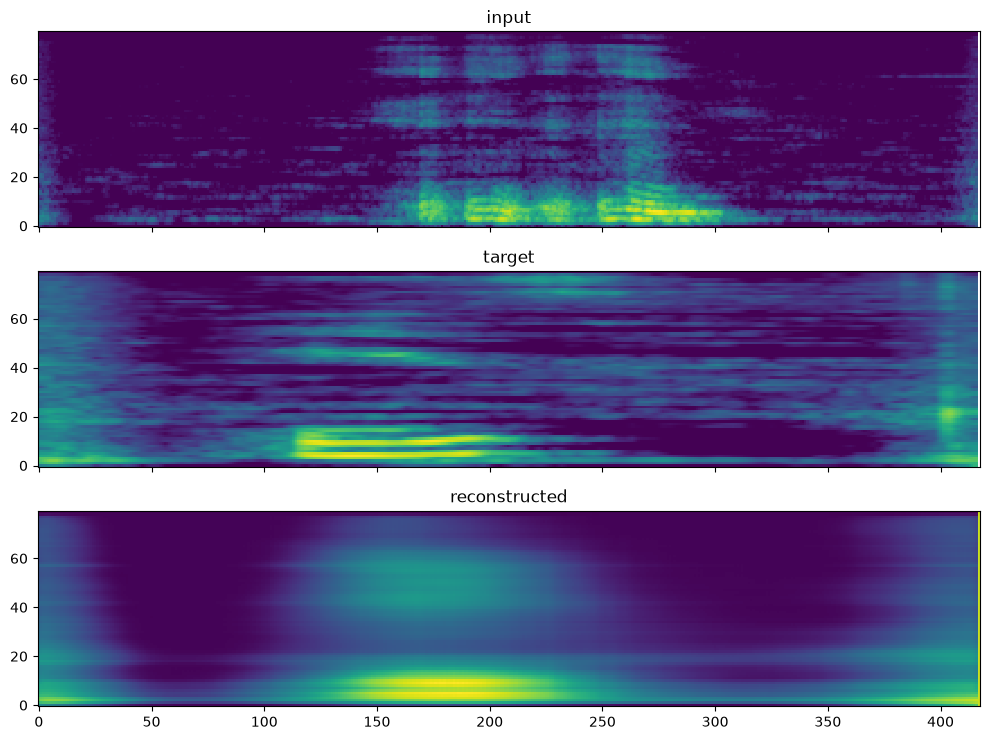

input


target


reconstructed


In [47]:
wavs, mels, info = reconstruct(INDEX)
results = evaluate_sample(*(torch.from_numpy(wavs[k]) for k in ('input', 'reconstructed', 'target')))
print(results)
print(INDEX,info)

fig, axes = plt.subplots(len(mels), 1, figsize=(10, 2.5 * len(mels)), sharex=True)
for ax, (name, mel) in zip(axes, mels.items()):
    ax.imshow(mel, origin="lower", aspect="auto", interpolation="none")
    ax.set_title(name)
plt.tight_layout(); plt.show()

OUT_DIR.mkdir(exist_ok=True)
for name, wav in wavs.items():
    print(name)
    display(Audio(wav, rate=SR))
    sf.write(OUT_DIR / f"{MODE}_{INDEX}_{name}.wav", wav, SR)
    